# Do-It-Yourself

In this block, the DIY section is more straightforward: we have a few tasks, but they are all around the same dataset. The tasks incorporates all the bits and pieces we have seen on the [hands-on](lab_D) section.

## Data preparation

For this section, we are going to revisit the AHAH dataset we saw in the [DIY section of Block D](../bD/diy_D). Please head over to the section to refresh your mind about how to load up the required data. Once you have successfully created the `ahah` {ref}`object <diy_D:ahah_read>`, move on to Task I.

In [31]:
import seaborn as sns
import pandas as pd
import esda
from pysal.lib import weights
from splot.esda import (
    moran_scatterplot, lisa_cluster, plot_local_autocorrelation
)
import geopandas as gpd
import numpy as np
import contextily as ctx
import matplotlib.pyplot as plt

In [32]:
# Read the file in
ahah = gpd.read_file("../data/Access_to_Healthy_Assets_and_Hazards_AHAH/Local_Authority_Districts/E08000012/shapefiles/E08000012.shp")
ahah_data = pd.read_csv("../data/Access_to_Healthy_Assets_and_Hazards_AHAH/Local_Authority_Districts/E08000012/tables/E08000012.csv")
ahah.head()
ahah_data.head()

,lsoa11cd,lsoa11nm,r_rank,h_rank,g_rank,e_rank,r_exp,h_exp,g_exp,e_exp,ahah,r_ahah,d_ahah,r_dec,h_dec,g_dec,e_dec,gpp_dist,ed_dist,dent_dist,pharm_dist,gamb_dist,ffood_dist,pubs_dist,leis_dist,blue_dist,off_dist,tobac_dist,green_pas,green_act,ur,no2_mean,pm10_mean,so2_mean,d_gpp_dist,d_ed_dist,d_pharm_dist,d_dent_dist,d_gamb_dist,d_ffood_dist,d_pubs_dist,d_leis_dist,d_blue_dist,d_off_dist,d_tobac_dist,d_green_pas,d_green_act,d_no2_mean,d_pm10_mean,d_so2_mean
0,E01006512,Liverpool 031A,31239,3055,31351,35965,30.888481,1.725173,31.123073,43.744800,26.870382,32211,8,8,1,8,9,0.488000,2.173200,0.500000,0.383200,1.007200,0.786000,0.689600,1.513600,3.945200,1.020000,1.506400,0.068356,0.34,1,15.393118,11.078652,1.950664,2,1,1,2,6,7,8,4,9,9,8,9,3,9,4,10
1,E01006513,Liverpool 060A,41456,2213,37636,35878,90.685995,1.236631,50.819353,43.429892,46.542967,41551,10,10,1,10,9,0.363878,1.713878,0.947755,0.424796,0.344286,0.169082,0.135204,0.643571,4.256122,0.343163,0.576531,0.068129,0.72,1,15.298441,11.156717,1.932047,1,1,2,5,10,10,10,1,9,10,10,9,8,9,4,10
2,E01006514,Liverpool 037A,37258,4510,39228,35143,49.017998,2.594648,60.485044,40.928662,38.256588,39958,10,9,2,10,9,0.390000,2.195000,0.920870,0.636087,0.646739,0.555870,0.394783,0.959348,5.756739,0.602609,0.971739,0.060324,0.80,1,14.745196,11.072998,1.915470,1,1,4,4,8,8,9,2,10,10,9,9,9,9,4,10
3,E01006515,Liverpool 037B,34254,6931,29900,35065,38.227117,4.118458,28.254809,40.678514,27.819724,33425,9,9,2,8,9,0.588906,2.813906,1.238125,0.850938,0.730000,0.597812,0.528281,0.477344,6.497031,1.105000,1.261562,0.052696,0.20,1,14.638801,10.953093,1.938072,2,2,5,6,8,8,9,1,10,8,9,9,1,9,4,10
4,E01006518,Liverpool 044A,25433,7533,37244,34392,21.166678,4.513573,48.953916,38.626230,28.315099,34019,9,7,2,9,9,0.850000,3.314286,1.141905,0.401667,0.755476,1.373333,1.317857,0.976905,5.781190,1.625000,1.764524,0.109755,0.65,1,14.274426,10.979651,1.898769,4,2,2,5,8,5,5,2,10,7,7,8,8,8,4,10


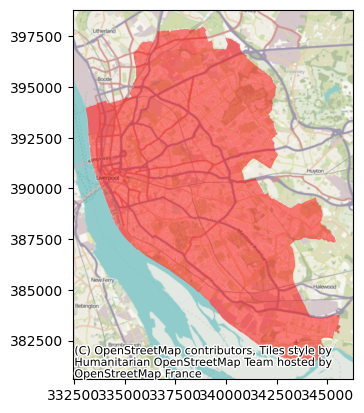

In [33]:
# Index table on the lsoa11cd
ahah = ahah.set_index("lsoa11cd", drop=False)

#Plot data
ax = ahah.plot(alpha=0.5, color='red');
# Add background map, expressing target CRS so the basemap can be
# reprojected (warped)
ctx.add_basemap(ax, crs=ahah.crs)

## Task I: get the dataset ready

With the `ahah` table on your figertips, complete all the other bits required for the ESDA analysis of spatial autocorrelation:

- Make sure your geography does not have islands
```{margin}
:class: tip
When creating your spatial weights matrix, think of one criterium to build it that you think would fit this variable (e.g. contiguity, distance-based, etc.), and apply it.
```
- Create a spatial weights matrix
- Standardise the spatial weights matrix
- Create the standardised version of the AHAH score
- Create the spatial lag of the main AHAH score


In [34]:
# Create the spatial weights matrix
%time w = weights.Queen.from_dataframe(ahah, ids="lsoa11cd")
w['E01006512']

CPU times: user 350 ms, sys: 26.8 ms, total: 376 ms
Wall time: 344 ms


{'E01033757': 1.0,
 'E01006751': 1.0,
 'E01006513': 1.0,
 'E01006673': 1.0,
 'E01006679': 1.0,
 'E01033768': 1.0}

In [35]:
# Drop islands
ahah = ahah.drop(w.islands)

In [36]:
# Row standardize matrix
w.transform = 'R'
w['E01006512']

{'E01033757': 0.16666666666666666,
 'E01006751': 0.16666666666666666,
 'E01006513': 0.16666666666666666,
 'E01006673': 0.16666666666666666,
 'E01006679': 0.16666666666666666,
 'E01033768': 0.16666666666666666}

In [37]:
#Join CSV with spatial data
ahah = ahah.reset_index("lsoa11cd", drop=True)
ahah_join = ahah.merge(ahah_data, on="lsoa11cd", how="left")
pd.set_option("display.max_columns", None)
ahah_join.head()

,lsoa11cd,geometry,lsoa11nm,r_rank,h_rank,g_rank,e_rank,r_exp,h_exp,g_exp,e_exp,ahah,r_ahah,d_ahah,r_dec,h_dec,g_dec,e_dec,gpp_dist,ed_dist,dent_dist,pharm_dist,gamb_dist,ffood_dist,pubs_dist,leis_dist,blue_dist,off_dist,tobac_dist,green_pas,green_act,ur,no2_mean,pm10_mean,so2_mean,d_gpp_dist,d_ed_dist,d_pharm_dist,d_dent_dist,d_gamb_dist,d_ffood_dist,d_pubs_dist,d_leis_dist,d_blue_dist,d_off_dist,d_tobac_dist,d_green_pas,d_green_act,d_no2_mean,d_pm10_mean,d_so2_mean
0,E01006512,"POLYGON ((336103.358 389628.580, 336103.416 38...",Liverpool 031A,31239,3055,31351,35965,30.888481,1.725173,31.123073,43.744800,26.870382,32211,8,8,1,8,9,0.488000,2.173200,0.500000,0.383200,1.007200,0.786000,0.689600,1.513600,3.945200,1.020000,1.506400,0.068356,0.34,1,15.393118,11.078652,1.950664,2,1,1,2,6,7,8,4,9,9,8,9,3,9,4,10
1,E01006513,"POLYGON ((335173.781 389691.538, 335169.798 38...",Liverpool 060A,41456,2213,37636,35878,90.685995,1.236631,50.819353,43.429892,46.542967,41551,10,10,1,10,9,0.363878,1.713878,0.947755,0.424796,0.344286,0.169082,0.135204,0.643571,4.256122,0.343163,0.576531,0.068129,0.72,1,15.298441,11.156717,1.932047,1,1,2,5,10,10,10,1,9,10,10,9,8,9,4,10
2,E01006514,"POLYGON ((335495.676 389697.267, 335495.444 38...",Liverpool 037A,37258,4510,39228,35143,49.017998,2.594648,60.485044,40.928662,38.256588,39958,10,9,2,10,9,0.390000,2.195000,0.920870,0.636087,0.646739,0.555870,0.394783,0.959348,5.756739,0.602609,0.971739,0.060324,0.80,1,14.745196,11.072998,1.915470,1,1,4,4,8,8,9,2,10,10,9,9,9,9,4,10
3,E01006515,"POLYGON ((334953.001 389029.000, 334951.000 38...",Liverpool 037B,34254,6931,29900,35065,38.227117,4.118458,28.254809,40.678514,27.819724,33425,9,9,2,8,9,0.588906,2.813906,1.238125,0.850938,0.730000,0.597812,0.528281,0.477344,6.497031,1.105000,1.261562,0.052696,0.20,1,14.638801,10.953093,1.938072,2,2,5,6,8,8,9,1,10,8,9,9,1,9,4,10
4,E01006518,"POLYGON ((335354.015 388601.947, 335354.000 38...",Liverpool 044A,25433,7533,37244,34392,21.166678,4.513573,48.953916,38.626230,28.315099,34019,9,7,2,9,9,0.850000,3.314286,1.141905,0.401667,0.755476,1.373333,1.317857,0.976905,5.781190,1.625000,1.764524,0.109755,0.65,1,14.274426,10.979651,1.898769,4,2,2,5,8,5,5,2,10,7,7,8,8,8,4,10


In [38]:
# Standardize the ahah_join score
ahah_join['ahah_std'] = (
    ahah_join['ahah'] - ahah_join['ahah'].mean()
) / ahah_join['ahah'].std()

In [39]:
# Create spatial lag
ahah_join['w_ahah_std'] = weights.lag_spatial(w, ahah_join['ahah_std'])
ahah_join.head()

,lsoa11cd,geometry,lsoa11nm,r_rank,h_rank,g_rank,e_rank,r_exp,h_exp,g_exp,e_exp,ahah,r_ahah,d_ahah,r_dec,h_dec,g_dec,e_dec,gpp_dist,ed_dist,dent_dist,pharm_dist,gamb_dist,ffood_dist,pubs_dist,leis_dist,blue_dist,off_dist,tobac_dist,green_pas,green_act,ur,no2_mean,pm10_mean,so2_mean,d_gpp_dist,d_ed_dist,d_pharm_dist,d_dent_dist,d_gamb_dist,d_ffood_dist,d_pubs_dist,d_leis_dist,d_blue_dist,d_off_dist,d_tobac_dist,d_green_pas,d_green_act,d_no2_mean,d_pm10_mean,d_so2_mean,ahah_std,w_ahah_std
0,E01006512,"POLYGON ((336103.358 389628.580, 336103.416 38...",Liverpool 031A,31239,3055,31351,35965,30.888481,1.725173,31.123073,43.744800,26.870382,32211,8,8,1,8,9,0.488000,2.173200,0.500000,0.383200,1.007200,0.786000,0.689600,1.513600,3.945200,1.020000,1.506400,0.068356,0.34,1,15.393118,11.078652,1.950664,2,1,1,2,6,7,8,4,9,9,8,9,3,9,4,10,0.226898,0.708614
1,E01006513,"POLYGON ((335173.781 389691.538, 335169.798 38...",Liverpool 060A,41456,2213,37636,35878,90.685995,1.236631,50.819353,43.429892,46.542967,41551,10,10,1,10,9,0.363878,1.713878,0.947755,0.424796,0.344286,0.169082,0.135204,0.643571,4.256122,0.343163,0.576531,0.068129,0.72,1,15.298441,11.156717,1.932047,1,1,2,5,10,10,10,1,9,10,10,9,8,9,4,10,3.311056,1.505995
2,E01006514,"POLYGON ((335495.676 389697.267, 335495.444 38...",Liverpool 037A,37258,4510,39228,35143,49.017998,2.594648,60.485044,40.928662,38.256588,39958,10,9,2,10,9,0.390000,2.195000,0.920870,0.636087,0.646739,0.555870,0.394783,0.959348,5.756739,0.602609,0.971739,0.060324,0.80,1,14.745196,11.072998,1.915470,1,1,4,4,8,8,9,2,10,10,9,9,9,9,4,10,2.011963,1.004101
3,E01006515,"POLYGON ((334953.001 389029.000, 334951.000 38...",Liverpool 037B,34254,6931,29900,35065,38.227117,4.118458,28.254809,40.678514,27.819724,33425,9,9,2,8,9,0.588906,2.813906,1.238125,0.850938,0.730000,0.597812,0.528281,0.477344,6.497031,1.105000,1.261562,0.052696,0.20,1,14.638801,10.953093,1.938072,2,2,5,6,8,8,9,1,10,8,9,9,1,9,4,10,0.375731,1.531162
4,E01006518,"POLYGON ((335354.015 388601.947, 335354.000 38...",Liverpool 044A,25433,7533,37244,34392,21.166678,4.513573,48.953916,38.626230,28.315099,34019,9,7,2,9,9,0.850000,3.314286,1.141905,0.401667,0.755476,1.373333,1.317857,0.976905,5.781190,1.625000,1.764524,0.109755,0.65,1,14.274426,10.979651,1.898769,4,2,2,5,8,5,5,2,10,7,7,8,8,8,4,10,0.453393,0.051154


## Task II: global spatial autocorrelation

Let's move on to the analytics:

- Visualise the main AHAH score with a Moran Plot
- Calculate Moran's I
- *What conclusions can you reach from the Moran Plot and Moran's I? What's the main spatial pattern?*

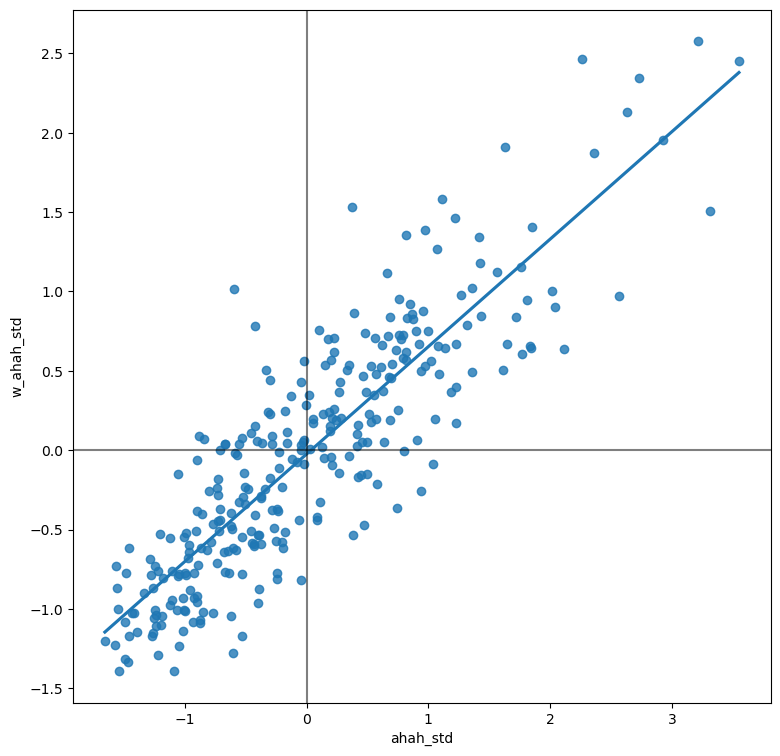

In [40]:
# Create Moran Plot
# Setup the figure and axis
f, ax = plt.subplots(1, figsize=(9, 9))
# Plot values
sns.regplot(x='ahah_std', y='w_ahah_std', data=ahah_join, ci=None)
# Add vertical and horizontal lines
plt.axvline(0, c='k', alpha=0.5)
plt.axhline(0, c='k', alpha=0.5)
# Display
plt.show()

In [41]:
mi = esda.Moran(ahah_join['ahah'], w)

In [42]:
mi.I

0.6770361378406533

Answer: The 0.677 Moran value indicates that there is a strong positive autocorrelation between neighbors. Neighborhoods who have a high AHAH value are more likely to be next to neighborhoods with similar AHAH statistics. The same goes for neighborhoods with low AHAH statistics.

## Task III: local spatial autocorrelation

Now that you have a good sense of the overall pattern in the AHAH dataset, let's move to the local scale:

- Calculate LISA statistics for the LSOA areas
- Make a map of significant clusters at the 5%
- *Can you identify hotspots or coldspots? If so, what do they mean? What about spatial outliers?*
````{margin}
```{warning}
The last action is a bit more sophisticated, put all your brain power into it and you'll achieve it!
```
````
- Create cluster maps for significance levels 1% and 10%; compare them with the one we obtained. *What are the main changes? Why?*

In [45]:
lisa = esda.Moran_Local(ahah_join['ahah'], w)
# Break observations into significant or not
ahah_join['significant'] = lisa.p_sim < 0.05
# Store the quadrant they belong to
ahah_join['quadrant'] = lisa.q

In [47]:
ahah_join['significant'].head()

0     True
1     True
2     True
3     True
4    False
Name: significant, dtype: bool

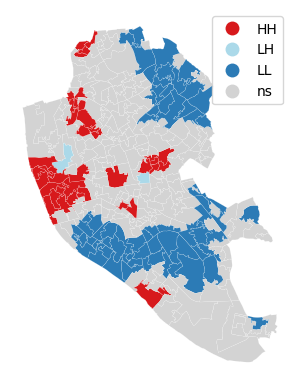

In [48]:
lisa_cluster(lisa, ahah_join);

Answer:

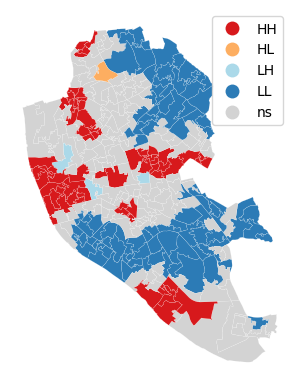

In [53]:
# Break observations into significant or not 10%
lisa_cluster(lisa, ahah_join, p=0.1);

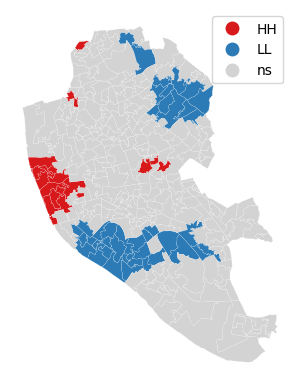

In [54]:
# Break observations into significant or not 1%
lisa_cluster(lisa, ahah_join, p=0.01);

In [52]:
help(lisa_cluster)

Help on function lisa_cluster in module splot._viz_esda_mpl:

lisa_cluster(moran_loc, gdf, p=0.05, ax=None, legend=True, legend_kwds=None, **kwargs)
    Create a LISA Cluster map
    
    Parameters
    ----------
    moran_loc : esda.moran.Moran_Local or Moran_Local_BV instance
        Values of Moran's Local Autocorrelation Statistic
    gdf : geopandas dataframe instance
        The Dataframe containing information to plot. Note that `gdf` will be
        modified, so calling functions should use a copy of the user
        provided `gdf`. (either using gdf.assign() or gdf.copy())
    p : float, optional
        The p-value threshold for significance. Points will
        be colored by significance.
    ax : matplotlib Axes instance, optional
        Axes in which to plot the figure in multiple Axes layout.
        Default = None
    legend : boolean, optional
        If True, legend for maps will be depicted. Default = True
    legend_kwds : dict, optional
        Dictionary to contr